In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

# Jika dijalankan di Google Colab, aktifkan baris berikut:
# from google.colab import drive
# drive.mount('/content/drive')
print('Library berhasil diimpor dengan sukses!')

Library berhasil diimpor dengan sukses!


In [2]:
# Load images and labels from a directory structure
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in p.glob('*'):
        if folder.is_dir():
            label = folder.name
            for file in folder.glob('*.jpg'):
                img = cv2.imread(str(file))
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img_list.append((img, label))
    return img_list

train_dir = "images/training/"
test_dir  = "images/test/"

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

print(f"Jumlah data training: {len(train_img)}")
print(f"Jumlah data testing: {len(test_img)}")

Jumlah data training: 240
Jumlah data testing: 160


In [3]:
# Preprocess images: resize and encode labels
def resize_image(img, size=(256, 256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

print(f"Jumlah citra X_train: {len(X_train_img)}, label y_train: {len(y_train)}")
print(f"Jumlah citra X_test: {len(X_test_img)}, label y_test: {len(y_test)}")

Jumlah citra X_train: 240, label y_train: 240
Jumlah citra X_test: 160, label y_test: 160


In [4]:
# Extract HOG features
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8, 8),
                       cells_per_block=(2, 2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)

print("Shape X_train_feat:", X_train_feat.shape)
print("Shape X_test_feat :", X_test_feat.shape)

Shape X_train_feat: (240, 34596)
Shape X_test_feat : (160, 34596)


In [5]:
# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

print("Mean scaler (5 fitur pertama):", scaler.mean_[:5])

Mean scaler (5 fitur pertama): [0.2170476  0.07523279 0.09602815 0.07937949 0.20268199]


In [6]:
# Split training data for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

print(f"Data train: {X_train.shape[0]} sampel")
print(f"Data val  : {X_val.shape[0]} sampel")

Data train: 192 sampel
Data val  : 48 sampel


In [7]:
# Convert labels to numpy arrays (required for Keras)
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

print("Tipe data y_train:", type(y_train), y_train.shape)
print("Tipe data y_val  :", type(y_val), y_val.shape)
print("Tipe data y_test :", type(y_test), y_test.shape)

Tipe data y_train: <class 'numpy.ndarray'> (192,)
Tipe data y_val  : <class 'numpy.ndarray'> (48,)
Tipe data y_test : <class 'numpy.ndarray'> (160,)


In [8]:
# Build a simple feedforward neural network
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Train the model
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 0.8385 - loss: 0.5014 - val_accuracy: 0.8750 - val_loss: 0.1867
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 1.0000 - loss: 0.0097 - val_accuracy: 0.9792 - val_loss: 0.0485
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 1.0000 - loss: 3.0700e-04 - val_accuracy: 0.9792 - val_loss: 0.0188
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 1.0000 - loss: 5.4548e-04 - val_accuracy: 1.0000 - val_loss: 0.0062
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 1.0000 - loss: 1.1779e-06 - val_accuracy: 1.0000 - val_loss: 0.0027
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 1.0000 - loss: 1.4542e-06 - val_accuracy: 1.0000 - val_loss: 0.0016
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 1.0000 - loss: 1.5019e-06 - val_accuracy: 1.0000 - val_loss: 0.0012
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 1.0000 - loss: 1.4447e-06 - val_accuracy: 1.

In [10]:
# Evaluate the model on test data
test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
print("Akurasi Test:", test_acc)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9438 - loss: 0.8095 
Akurasi Test: 0.9437500238418579


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

   Night (0)       0.94      0.95      0.94        80
     Day (1)       0.95      0.94      0.94        80

    accuracy                           0.94       160
   macro avg       0.94      0.94      0.94       160
weighted avg       0.94      0.94      0.94       160

--- CONFUSION MATRIX ---
[[76  4]
 [ 5 75]]


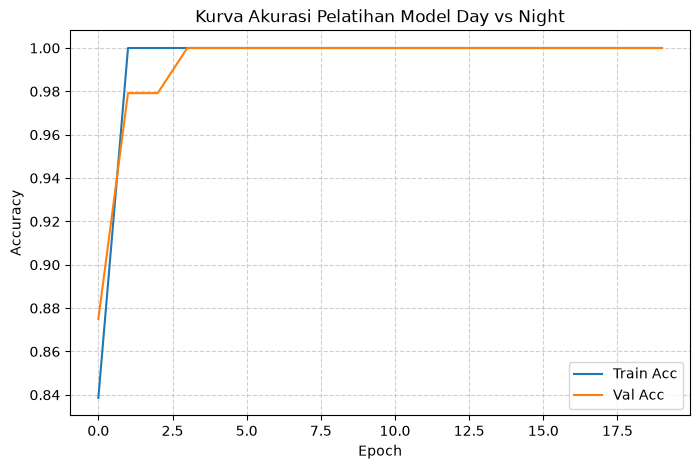

In [11]:
# Generate classification report and confusion matrix
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print("--- CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_pred, target_names=['Night (0)', 'Day (1)']))
print("--- CONFUSION MATRIX ---")
print(confusion_matrix(y_test, y_pred))

# Visualize training history
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Kurva Akurasi Pelatihan Model Day vs Night')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

In [12]:
# Save the trained model
import pickle

# 1. Simpan Model
# Menggunakan format .h5
model.save('day_night_model.h5')
print(" Model berhasil disimpan sebagai: day_night_model.h5")

# 2. Simpan Scaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print(" Scaler berhasil disimpan sebagai: scaler.pkl")

 Model berhasil disimpan sebagai: day_night_model.h5
 Scaler berhasil disimpan sebagai: scaler.pkl
